# Impuestos sobre el patrimonio y las herencias y empresas de alto crecimiento

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "impuestos-patrimonio-empresas-alto-crecimiento"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Impuestos sobre el patrimonio y las herencias y empresas de alto crecimiento"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Impuestos sobre el patrimonio y las herencias", "unidad": "% del patrimonio neto de los hogares"}
EJE_Y = {"titulo": "Empresas de alto crecimiento", "unidad": "% de las empresas con 10 o más asalariados"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 4  # 4 porque los valores son centésimas de punto; decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE.

- **Eje horizontal:** un **tipo implícito**: lo que recaudan las administraciones públicas por **impuestos periódicos sobre el patrimonio neto de las personas** (categoría 4210 de la OCDE; en España, el Impuesto sobre el Patrimonio y el de Grandes Fortunas) y por **impuestos sobre sucesiones, herencias y donaciones** (categoría 4300), en porcentaje del **patrimonio neto de los hogares** (viviendas, suelo y activos financieros menos deudas, según las cuentas nacionales). Es lo que se paga de media por cada 100 euros de patrimonio, no el tipo que fija la ley.
- **Eje vertical:** el porcentaje de **empresas de alto crecimiento**: empresas con al menos 10 asalariados que aumentan su plantilla más de un 10 % al año durante tres años seguidos.

**Para qué sirve.** Pone junto al peso de los impuestos sobre la riqueza el de las empresas que crecen deprisa, el argumento de quienes sostienen que esos impuestos desincentivan la inversión y el emprendimiento. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.** Las empresas de alto crecimiento solo se publican para parte de los países de la OCDE (sobre todo europeos) y con años distintos; cada punto usa el último año en que el país tiene dato en los dos ejes. Dividir entre el patrimonio evita que el eje dependa de cuánta riqueza hay en cada país, pero el tipo implícito refleja a la vez los tipos legales, los mínimos exentos, las bonificaciones y la elusión; no es el tipo legal, que la OCDE no publica de forma comparable (cada impuesto tiene sus tramos y, en España, cada comunidad los suyos). El patrimonio solo cuenta las viviendas, el suelo y el patrimonio financiero neto: deja fuera otros activos no financieros de los hogares, como los de los negocios de autónomos, que suelen pesar poco.

## 2. Descarga

- **OCDE, Revenue Statistics** (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): ingresos fiscales (`TAX_REV`) de las administraciones públicas (`S13`) en moneda nacional (`XDC`), categorías `T_4200`, `T_4210` y `T_4300`, de los 38 países de la OCDE.
- **OCDE, balances de los activos no financieros** (`OECD.SDD.NAD,DSD_NASEC10@DF_TABLE9B`, versión 1.1): viviendas (`N111N`) y suelo (`N211N`) de los hogares e instituciones sin fines de lucro (`S1M`), en moneda nacional.
- **OCDE, balances financieros** (`OECD.SDD.NAD,DSD_NASEC20@DF_T720R_A`, versión 1.1): patrimonio financiero neto (`BF90`) del mismo sector, en moneda nacional.
- **OCDE, demografía empresarial** (`OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG`, versión 1.0): empresas de alto crecimiento (`HGE10`, `PT_ENT10`, `S_GE10`) de la actividad `BTNXK`.
- **Contrastes para las notas:** España en Eurostat (`bd_hgnace_r`), qué publica la OCDE de Canadá y la tasa de natalidad de empresas de España (`DF_BD_EMP_B_D`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Empresas de alto crecimiento (demografía empresarial de la OCDE)
DATAFLOW_HG = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0"
# Dimensiones: frecuencia . país . medida (empresas) . actividad . tamaño (10 o más asalariados) . edad (todas)
#              . tipo (empresas con asalariados) . fase (crecimiento del empleo de más del 10 % anual) . unidad
ACTIVIDAD = "BTNXK"  # economía empresarial (secciones B a N de la CIIU/NACE) salvo actividades financieras y de seguros
CLAVE_HG = "A.{AREA}." + f"ENT.{ACTIVIDAD}.S_GE10._T.ENT_EMP.HGE10.PT_ENT10"
# Tasa de natalidad de las empresas con asalariados (solo notas)
DATAFLOW_NAT = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_B_D,1.0"
CLAVE_NAT = "A.{AREA}." + f"ENT.{ACTIVIDAD}._T.Y_LT1.ENT_EMP.B.PT_ENT_EM"


def descargar_hg():
    return oecd.get(DATAFLOW_HG, CLAVE_HG, areas=AREAS, desde=DESDE)


def otras_definiciones_hg(area):
    """Qué publica la OCDE de empresas de alto crecimiento para un país sin la definición de la gráfica.

    Con reintentos (`pedir`) y sin tragarse errores: si la consulta falla, el notebook falla en vez
    de escribir unas notas distintas.
    """
    import io

    import requests

    from lib._http import pedir

    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW_HG}/A.{area}.ENT.......", None,
        error_cls=oecd.OecdError, etiqueta=f"empresas de alto crecimiento de {area}",
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


def descargar_hg_eurostat():
    """Contraste de España con Eurostat (bd_hgnace_r)."""
    return eurostat.get(
        "bd_hgnace_r", {"freq": "A", "indic_sbs": "ENT_HGRWR_PC", "nace_r2": "B-S_X_O_S94"},
        geos={"ES": "ESP"}, desde=DESDE,
    )


def descargar_natalidad():
    return oecd.get(DATAFLOW_NAT, CLAVE_NAT, areas={"ESP": "ESP"}, desde=DESDE)[0]

# Revenue Statistics de la OCDE: país . medida . sector . categoría . código nacional . unidad . frecuencia
DATAFLOW_REV = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
CLAVE_REV = "{AREA}.TAX_REV.S13.{CATEGORIA}._T.XDC.A"
# 4210: patrimonio neto de las personas (no la 4220, de las sociedades, que no grava el patrimonio de los hogares);
# la OCDE solo separa 4210 y 4220 en algunos países: en el resto se usa el total 4200
CATEGORIAS = ("T_4200", "T_4210", "T_4300")
# Patrimonio de los hogares e ISFLSH (S1M): viviendas y suelo (balances no financieros) y patrimonio financiero neto
DATAFLOW_NF = "OECD.SDD.NAD,DSD_NASEC10@DF_TABLE9B,1.1"
# Dimensiones: frecuencia . país . sector . contrapartida . activo . operación . instrumento . gasto . unidad
#              . valoración . precios . transformación . tabla
CLAVE_NF = "A.{AREA}.S1M..A._Z.{ACTIVO}._Z.XDC._Z.V.N."
ACTIVOS_NF = ("N111N", "N211N")  # viviendas; suelo (sobre todo el de las viviendas)
DATAFLOW_FIN = "OECD.SDD.NAD,DSD_NASEC20@DF_T720R_A,1.1"
# Patrimonio financiero neto (BF90, saldo de activos menos pasivos financieros), sin consolidar
CLAVE_FIN = "A..{AREA}..S1M.S1.N.N.LE.BF90..XDC......"

# `unidades=True`: Revenue Statistics publica en miles de millones y las cuentas nacionales en millones
categorias = pd.concat(
    [
        oecd.get(DATAFLOW_REV, CLAVE_REV.replace("{CATEGORIA}", c), areas=AREAS, desde=DESDE, unidades=True)[0]
        .assign(categoria=c)
        for c in CATEGORIAS
    ],
    ignore_index=True,
)
patrimonio = pd.concat(
    [
        *(
            oecd.get(DATAFLOW_NF, CLAVE_NF.replace("{ACTIVO}", a), areas=AREAS, desde=DESDE, unidades=True)[0]
            .assign(componente=a)
            for a in ACTIVOS_NF
        ),
        oecd.get(DATAFLOW_FIN, CLAVE_FIN, areas=AREAS, desde=DESDE, unidades=True)[0].assign(componente="BF90"),
    ],
    ignore_index=True,
)
y, _ = descargar_hg()
hg_eurostat, _ = descargar_hg_eurostat()
natalidad = descargar_natalidad()
otras_can = otras_definiciones_hg("CAN")

## 3. Transformación

1. **Eje x:** se suman la categoría 4210 (o la 4200, en los países en los que la OCDE no separa personas y sociedades) y la 4300 de cada país y año (un 0 publicado por la OCDE es un dato y entra en la suma; si falta una de las dos, el año queda sin dato) y se dividen entre el patrimonio neto de los hogares del mismo año: viviendas + suelo + patrimonio financiero neto, los tres en moneda nacional (si falta uno, no hay dato). Se multiplica por 100.
2. **Eje y:** tal como lo publica la OCDE.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

In [ ]:

def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_hg(y, hg_eurostat, natalidad, otras_can):
    """Notas comunes del eje de las empresas de alto crecimiento."""
    _, flujo, version = DATAFLOW_HG.split(",")
    notas = [
        f"Empresas de alto crecimiento: OCDE, demografía empresarial ({flujo}, versión {version}): empresas con al "
        "menos 10 asalariados al inicio del periodo cuyo número de asalariados crece de media más de un 10 % al año "
        "durante tres años, en porcentaje de las empresas con al menos 10 asalariados (HGE10, PT_ENT10, S_GE10).",
        f"Actividad: economía empresarial salvo actividades financieras y de seguros ({ACTIVIDAD}, secciones B a N "
        "salvo K), el agregado de actividad con más países de la OCDE en esta definición.",
        "Mide el crecimiento del empleo, no el de la facturación, y no cuenta las empresas sin asalariados ni las "
        "que no crecen, a diferencia de la tasa de natalidad de empresas.",
    ]
    can = otras_can
    if len(can) and "HGE10" not in set(can["BUSINESS_STAGE"]):
        etapas = sorted(set(can["BUSINESS_STAGE"]) & {"HGE20", "HGT20", "HGE10T20"})
        notas.append(
            "Canadá no aparece: la OCDE solo publica sus empresas de alto crecimiento con otra definición "
            f"({unir(etapas)}: crecimiento de más del 20 % anual), sin la del 10 % de esta gráfica."
        )
    esp = y[y["serie"] == "ESP"].set_index("periodo")["valor"]
    eu = hg_eurostat.set_index("periodo")["valor"]
    comunes = sorted(set(esp.index) & set(eu.index))
    if comunes:
        a = comunes[-1]
        notas.append(
            f"España en Eurostat (bd_hgnace_r, industria, construcción y servicios salvo administración pública y "
            f"asociaciones, B-S_X_O_S94): {es(eu[a], 2)} % en {a}, frente al {es(esp[a], 2)} % de la OCDE ({ACTIVIDAD}); "
            "las dos fuentes no cubren las mismas actividades."
        )
    if len(natalidad):
        n = natalidad.sort_values("periodo").iloc[-1]
        notas.append(
            f"Tasa de natalidad de las empresas con asalariados de España (OCDE, {DATAFLOW_NAT.split(',')[1]}, "
            f"{ACTIVIDAD}): {es(n['valor'])} % de las empresas activas en {int(n['periodo'])}. No se usa en la gráfica: "
            "cuenta todas las empresas nuevas, también las pequeñas que no crecen."
        )
    return notas


# Patrimonio de las personas: 4210 si la OCDE la publica; si no, el total 4200 (sin separar personas y sociedades)
ancho = categorias.pivot_table(index=["serie", "periodo"], columns="categoria", values="valor")
personas = ancho["T_4210"].combine_first(ancho["T_4200"])
# Recaudación personas + 4300 (min_count=2: si falta una de las dos, no hay dato)
recaudacion = pd.concat([personas, ancho["T_4300"]], axis=1).sum(axis=1, min_count=2)
# Patrimonio neto de los hogares: viviendas + suelo + financiero neto (min_count=3: los tres o ninguno)
componentes = patrimonio.pivot_table(index=["serie", "periodo"], columns="componente", values="valor")
riqueza = componentes[[*ACTIVOS_NF, "BF90"]].sum(axis=1, min_count=3)
x = (
    (recaudacion / riqueza * 100).round(6).rename("valor").reset_index()
    .dropna(subset=["valor"])[["serie", "periodo", "valor"]]
)
_, FLUJO_REV, VERSION_REV = DATAFLOW_REV.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_REV} (Revenue Statistics, versión {VERSION_REV}): TAX_REV, S13, T_4210 (o T_4200) + T_4300, XDC", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{DATAFLOW_NF.split(',')[1]}: S1M, N111N + N211N, XDC", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{DATAFLOW_FIN.split(',')[1]}: S1M, BF90, XDC", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{DATAFLOW_HG.split(',')[1]}: HGE10, PT_ENT10, S_GE10, {ACTIVIDAD}", oecd.URL_EXPLORER, HOY),
]
con_punto = {
    p["codigo"] for p in construir_dispersion_data(
        x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=[],
        generado_por="", desde=DESDE, anios=ANIOS,
    )["puntos"]
}
# Países de la gráfica con 0 en el patrimonio de las personas en todos los años publicados
ceros = sorted(nombre_punto(c) for c in con_punto if (personas.loc[c].dropna() == 0).all())
# Países de la gráfica sin la 4210 y con recaudación en la 4200 (personas y sociedades juntas)
sin_desglose = sorted(
    nombre_punto(c) for c in con_punto
    if ancho.loc[c, "T_4210"].isna().all() and (ancho.loc[c, "T_4200"].dropna() > 0).any()
)
sin_patrimonio = sorted(
    nombre_punto(c) for c in PAISES
    if c in set(y["serie"]) and c not in set(riqueza.dropna().index.get_level_values("serie"))
)
NOTAS = [
    f"Impuestos sobre el patrimonio y las herencias: OCDE, Revenue Statistics ({FLUJO_REV}, versión {VERSION_REV}): suma "
    "de las categorías 4210 (impuestos periódicos sobre el patrimonio neto de las personas) y 4300 (sucesiones, "
    "herencias y donaciones) que recaudan las administraciones públicas, en porcentaje del patrimonio neto de los "
    "hogares del mismo año (tipo implícito: lo que se paga de media por cada 100 euros de patrimonio). No incluye el "
    "IBI (4100), los impuestos sobre transmisiones (4400) ni los impuestos sobre el patrimonio de las sociedades (4220).",
    f"Patrimonio neto de los hogares: OCDE, cuentas nacionales, hogares e instituciones sin fines de lucro al servicio "
    f"de los hogares (S1M): viviendas y suelo ({DATAFLOW_NF.split(',')[1]}, N111N y N211N) más el patrimonio financiero "
    f"neto ({DATAFLOW_FIN.split(',')[1]}, BF90), en moneda nacional. Deja fuera los demás activos no financieros de los "
    "hogares, que la OCDE publica para pocos países.",
    "Es un tipo medio implícito, no el tipo legal: refleja a la vez los tipos, los mínimos exentos, las bonificaciones "
    "y la elusión. La OCDE no publica de forma comparable los tipos legales de estos impuestos, que cambian con el "
    "patrimonio, el parentesco y, en España, la comunidad autónoma.",
]
NOTAS.append(
    "La OCDE solo separa el patrimonio de las personas (4210) y el de las sociedades (4220) en algunos países; en el "
    "resto se usa el total de la categoría 4200."
    + (f" Con recaudación en la 4200 sin separar: {unir(sin_desglose)}." if sin_desglose else "")
)
if ceros:
    NOTAS.append(
        f"La OCDE publica 0 en los impuestos periódicos sobre el patrimonio neto de las personas en todos los años de "
        f"{unir(ceros)}: su valor es solo la recaudación por sucesiones y donaciones."
    )
if sin_patrimonio:
    NOTAS.append(
        f"Sin el patrimonio de los hogares en las cuentas nacionales de la OCDE (viviendas, suelo o patrimonio "
        f"financiero): {unir(sin_patrimonio)}."
    )
NOTAS += notas_hg(y, hg_eurostat, natalidad, otras_can)

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

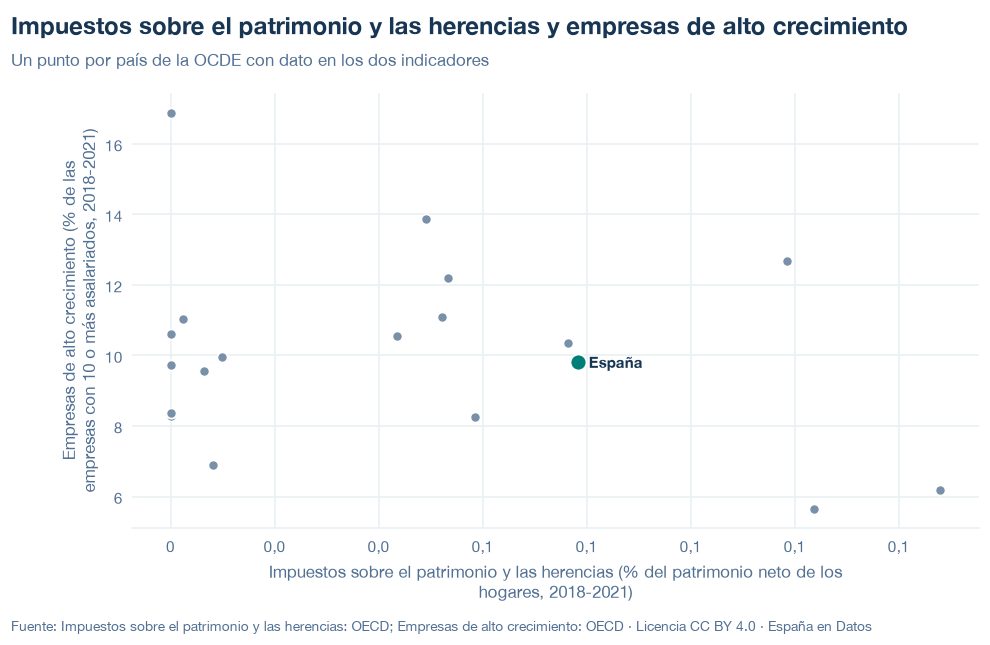

codigo  anio        x         y
   AUT  2021 0.000000  8.319125
   BEL  2021 0.123648  5.656941
   CZE  2021 0.000004  8.284117
   DEU  2021 0.058584  8.247173
   DNK  2021 0.049127 13.881402
   ESP  2021 0.078357  9.813936
   EST  2021 0.000000  9.720605
   FIN  2021 0.118564 12.693133
   FRA  2021 0.148036  6.194945
   GBR  2018 0.053325 12.210964
   HUN  2020 0.076461 10.340394
   ITA  2021 0.008224  6.895741
   LTU  2021 0.002379 11.026698
   LUX  2021 0.043614 10.541248
   NLD  2021 0.052189 11.084942
   POL  2021 0.009974  9.948272
   PRT  2021 0.000001 10.599048
   SVK  2021 0.000000  8.364553
   SVN  2021 0.006521  9.570008
   SWE  2021 0.000000 16.889853


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/impuestos-patrimonio-empresas-alto-crecimiento.json y data/impuestos-patrimonio-empresas-alto-crecimiento.csv


## 6. Fuentes, notas y licencia

- OCDE, Revenue Statistics: `OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0`, categorías `T_4200`, `T_4210` y `T_4300`, en moneda nacional.
- OCDE, cuentas nacionales por sectores: `OECD.SDD.NAD,DSD_NASEC10@DF_TABLE9B,1.1` (viviendas y suelo de los hogares) y `OECD.SDD.NAD,DSD_NASEC20@DF_T720R_A,1.1` (patrimonio financiero neto de los hogares).
- OCDE, demografía empresarial: `OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0` y `DF_BD_EMP_B_D` (natalidad, solo notas).
- Eurostat, `bd_hgnace_r` (contraste de España).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.